## Đề tài: Phân tích và dự đoán sức khỏe tâm thần thanh thiếu niên - Tanzania

Sức khỏe tâm thần ở thanh thiếu niên là vấn đề quan trọng, ảnh hưởng đến chất lượng cuộc sống, kết quả học tập và sự phát triển lâu dài. Phân tích dữ liệu khảo sát giúp khám phá các câu trả lời và các yếu tố liên quan trong phạm vi bộ dữ liệu.

Mục tiêu: Khám phá dữ liệu GSHS Tanzania 2014, kiểm tra chất lượng, phân tích câu trả lời Q24 và so sánh 5 mô hình phân loại. Mô hình chỉ phân loại câu trả lời khảo sát, không chẩn đoán hay sàng lọc lâm sàng.

In [1]:
#Khai báo thư viện
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
print("Đã import các thư viện thành công.")

Đã import các thư viện thành công.


## PHẦN 1: TỔNG QUAN VỀ TẬP DỮ LIỆU GSHS TANZANIA 2014 VÀ KIỂM TRA DỮ LIỆU KHUYẾT THIẾU

Notebook sử dụng `TZA2014_Public_Use.csv`, bộ dữ liệu Khảo sát sức khỏe học sinh toàn cầu (GSHS) tại Tanzania năm 2014. Tập dữ liệu gồm 3.793 bản ghi và 138 cột.

Các cột `q1` đến `q58` là câu trả lời khảo sát; `qn...` là các biến dẫn xuất; `weight`, `stratum` và `psu` mô tả thiết kế mẫu. Các phân tích dưới đây tập trung vào tuổi (Q1), giới tính (Q2), hành vi liên quan (Q15–Q17), cô đơn (Q22), lo lắng ảnh hưởng giấc ngủ (Q23), cân nhắc tự tử (Q24) và số bạn thân (Q27).

Codebook Tanzania cho biết mã Q24: `1 = Có`, `2 = Không`; Q22–Q23 có mã 1–5 theo mức tần suất; Q27 có mã 1–4 từ 0 đến 3 bạn trở lên. Kết quả mô tả chỉ đại diện cho mẫu khảo sát năm 2014. Phân tích không áp dụng trọng số, tầng mẫu hoặc cụm khảo sát.

In [2]:
# Đọc file CSV Tanzania
DATA_FILENAME = "TZA2014_Public_Use.csv"
search_roots = [Path.cwd(), *Path.cwd().parents]
CSV_PATH = next(
    (root / "data" / DATA_FILENAME for root in search_roots
     if (root / "data" / DATA_FILENAME).is_file()),
    None,
)
if CSV_PATH is None:
    raise FileNotFoundError(
        f"Không tìm thấy data/{DATA_FILENAME}. Hãy mở notebook trong workspace có thư mục data."
    )

df = pd.read_csv(CSV_PATH)
df.columns = df.columns.astype(str).str.strip().str.lower()
print("Quốc gia: Tanzania | Năm khảo sát: 2014")
print("Nguồn:", CSV_PATH)
print("Kích thước dữ liệu:", df.shape)
display(df.head())

Quốc gia: Tanzania | Năm khảo sát: 2014
Nguồn: /workspaces/python_report/data/TZA2014_Public_Use.csv
Kích thước dữ liệu: (3793, 138)


,q1,q2,q3,q4,q5,q6,q7,q8,q9,q10,q11,q12,q13,q14,q15,q16,q17,q18,q19,q20,q21,q22,q23,q24,q25,q26,q27,q28,q29,q30,q31,q32,q33,q34,q35,q36,q37,q38,q39,q40,q41,q42,q43,q44,q45,q46,q47,q48,q49,q50,q51,q52,q53,q54,q55,q56,q57,q58,qn6,qn7,qn8,qn9,qn10,qn11,qn12,qn13,qn14,qn15,qn16,qn17,qn18,qn19,qn20,qn21,qn22,qn23,qn24,qn25,qn26,qn27,qn28,qn29,qn30,qn31,qn32,qn33,qn34,qn35,qn36,qn37,qn38,qn39,qn40,qn41,qn42,qn43,qn44,qn45,qn46,qn47,qn48,qn49,qn50,qn51,qn52,qn53,qn54,qn55,qn56,qn57,qn58,qnfrlg,qnfr1g,qnfr2g,qnfr3g,qnveglg,qnveg1g,qnveg2g,qnveg3g,qnsodalg,qnsoda1g,qnsoda2g,qnsoda3g,qnff1g,qnff2g,qnff3g,qnc2g,qntob2g,qnnotb2g,qnbcanyg,qnc1g,qnpa5g,qnpa7g,qnpe3g,qnpe5g,weight,stratum,psu
0,2.0,2.0,1.0,NaN,NaN,1.0,3.0,3.0,2.0,1.0,5.0,4.0,4.0,4.0,3.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,4.0,1.0,1.0,1.0,1.0,5.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0,2.0,NaN,NaN,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,NaN,1.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0,1395.8235,201401025,49
1,2.0,2.0,1.0,NaN,NaN,1.0,3.0,7.0,4.0,1.0,5.0,5.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,4.0,1.0,1.0,1.0,1.0,5.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,1.0,1.0,NaN,2.0,1.0,6.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,NaN,NaN,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,NaN,1.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,2.0,NaN,NaN,2.0,NaN,NaN,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,1.0,1.0,1395.8235,201401025,49
2,4.0,2.0,1.0,NaN,NaN,2.0,1.0,3.0,3.0,1.0,6.0,5.0,2.0,2.0,NaN,1.0,1.0,1.0,1.0,2.0,1.0,3.0,3.0,2.0,2.0,2.0,4.0,1.0,1.0,1.0,1.0,5.0,1.0,NaN,1.0,1.0,1.0,1.0,NaN,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,8.0,1.0,6.0,1.0,5.0,2.0,5.0,5.0,4.0,4.0,2.0,1.0,2.0,2.0,1.0,1.0,2.0,1.0,1.0,NaN,2.0,2.0,NaN,NaN,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,NaN,2.0,2.0,NaN,1.0,2.0,NaN,2.0,NaN,NaN,2.0,NaN,NaN,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,1.0,2.0,2.0,1.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,1.0,1.0,1.0,1.0,1395.8235,201401025,49
3,4.0,2.0,1.0,NaN,NaN,1.0,4.0,5.0,3.0,2.0,3.0,4.0,5.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,3.0,1.0,6.0,1.0,1.0,5.0,5.0,4.0,4.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,NaN,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,NaN,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,1.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,1.0,1.0,1395.8235,201401025,49
4,2.0,2.0,1.0,NaN,NaN,1.0,4.0,4.0,3.0,1.0,5.0,5.0,5.0,5.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,5.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,3.0,1.0,1.0,2.0,3.0,3.0,4.0,4.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,NaN,NaN,2.0,NaN,2.0,2.0,2.0,2.0,2.0,1.0,NaN,2.0,2.0,NaN,1.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0,1395.8235,201401025,49


## 2. Kiểm tra cấu trúc dữ liệu

Mục tiêu:
- Xác định số lượng mẫu và số lượng biến.
- Quan sát các dòng dữ liệu đầu tiên.
- Kiểm tra kiểu dữ liệu của các biến.

In [3]:
# 1. Kích thước dữ liệu
print("Số dòng: ", df.shape[0])
print("Số cột: ", df.shape[1])

display(df.head(10))
display(df.tail())

Số dòng:  3793
Số cột:  138


,q1,q2,q3,q4,q5,q6,q7,q8,q9,q10,q11,q12,q13,q14,q15,q16,q17,q18,q19,q20,q21,q22,q23,q24,q25,q26,q27,q28,q29,q30,q31,q32,q33,q34,q35,q36,q37,q38,q39,q40,q41,q42,q43,q44,q45,q46,q47,q48,q49,q50,q51,q52,q53,q54,q55,q56,q57,q58,qn6,qn7,qn8,qn9,qn10,qn11,qn12,qn13,qn14,qn15,qn16,qn17,qn18,qn19,qn20,qn21,qn22,qn23,qn24,qn25,qn26,qn27,qn28,qn29,qn30,qn31,qn32,qn33,qn34,qn35,qn36,qn37,qn38,qn39,qn40,qn41,qn42,qn43,qn44,qn45,qn46,qn47,qn48,qn49,qn50,qn51,qn52,qn53,qn54,qn55,qn56,qn57,qn58,qnfrlg,qnfr1g,qnfr2g,qnfr3g,qnveglg,qnveg1g,qnveg2g,qnveg3g,qnsodalg,qnsoda1g,qnsoda2g,qnsoda3g,qnff1g,qnff2g,qnff3g,qnc2g,qntob2g,qnnotb2g,qnbcanyg,qnc1g,qnpa5g,qnpa7g,qnpe3g,qnpe5g,weight,stratum,psu
0,2.0,2.0,1.0,NaN,NaN,1.0,3.0,3.0,2.0,1.0,5.0,4.0,4.0,4.0,3.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,4.0,1.0,1.0,1.0,1.0,5.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0,2.0,NaN,NaN,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,NaN,1.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0,1395.8235,201401025,49
1,2.0,2.0,1.0,NaN,NaN,1.0,3.0,7.0,4.0,1.0,5.0,5.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,4.0,1.0,1.0,1.0,1.0,5.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,1.0,1.0,NaN,2.0,1.0,6.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,NaN,NaN,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,NaN,1.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,2.0,NaN,NaN,2.0,NaN,NaN,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,1.0,1.0,1395.8235,201401025,49
2,4.0,2.0,1.0,NaN,NaN,2.0,1.0,3.0,3.0,1.0,6.0,5.0,2.0,2.0,NaN,1.0,1.0,1.0,1.0,2.0,1.0,3.0,3.0,2.0,2.0,2.0,4.0,1.0,1.0,1.0,1.0,5.0,1.0,NaN,1.0,1.0,1.0,1.0,NaN,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,8.0,1.0,6.0,1.0,5.0,2.0,5.0,5.0,4.0,4.0,2.0,1.0,2.0,2.0,1.0,1.0,2.0,1.0,1.0,NaN,2.0,2.0,NaN,NaN,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,NaN,2.0,2.0,NaN,1.0,2.0,NaN,2.0,NaN,NaN,2.0,NaN,NaN,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,1.0,2.0,2.0,1.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,1.0,1.0,1.0,1.0,1395.8235,201401025,49
3,4.0,2.0,1.0,NaN,NaN,1.0,4.0,5.0,3.0,2.0,3.0,4.0,5.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,3.0,1.0,6.0,1.0,1.0,5.0,5.0,4.0,4.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,NaN,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,NaN,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,1.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,1.0,1.0,1395.8235,201401025,49
4,2.0,2.0,1.0,NaN,NaN,1.0,4.0,4.0,3.0,1.0,5.0,5.0,5.0,5.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,5.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,3.0,1.0,1.0,2.0,3.0,3.0,4.0,4.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,NaN,NaN,2.0,NaN,2.0,2.0,2.0,2.0,2.0,1.0,NaN,2.0,2.0,NaN,1.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0,1395.8235,201401025,49
5,4.0,1.0,1.0,NaN,NaN,3.0,4.0,4.0,1.0,1.0,2.0,2.0,5.0,3.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,6.0,5.0,1.0,2.0,3.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,2.0,2.0,1.0,1.0,2.0,NaN,NaN,2.0,NaN,2.0,2.0,1.0,2.0,2.0,2.0,NaN,2.0,2.0,NaN,2.0,1.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.

,q1,q2,q3,q4,q5,q6,q7,q8,q9,q10,q11,q12,q13,q14,q15,q16,q17,q18,q19,q20,q21,q22,q23,q24,q25,q26,q27,q28,q29,q30,q31,q32,q33,q34,q35,q36,q37,q38,q39,q40,q41,q42,q43,q44,q45,q46,q47,q48,q49,q50,q51,q52,q53,q54,q55,q56,q57,q58,qn6,qn7,qn8,qn9,qn10,qn11,qn12,qn13,qn14,qn15,qn16,qn17,qn18,qn19,qn20,qn21,qn22,qn23,qn24,qn25,qn26,qn27,qn28,qn29,qn30,qn31,qn32,qn33,qn34,qn35,qn36,qn37,qn38,qn39,qn40,qn41,qn42,qn43,qn44,qn45,qn46,qn47,qn48,qn49,qn50,qn51,qn52,qn53,qn54,qn55,qn56,qn57,qn58,qnfrlg,qnfr1g,qnfr2g,qnfr3g,qnveglg,qnveg1g,qnveg2g,qnveg3g,qnsodalg,qnsoda1g,qnsoda2g,qnsoda3g,qnff1g,qnff2g,qnff3g,qnc2g,qntob2g,qnnotb2g,qnbcanyg,qnc1g,qnpa5g,qnpa7g,qnpe3g,qnpe5g,weight,stratum,psu
3788,5.0,2.0,4.0,1.45,39.0,2.0,3.0,4.0,3.0,3.0,4.0,5.0,4.0,4.0,1.0,1.0,1.0,1.0,1.0,2.0,5.0,3.0,1.0,2.0,2.0,1.0,3.0,1.0,1.0,1.0,1.0,NaN,1.0,NaN,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,4.0,1.0,1.0,1.0,1.0,4.0,4.0,4.0,4.0,4.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,NaN,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,NaN,NaN,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0,941.8193,201401001,1
3789,6.0,2.0,4.0,1.39,40.0,1.0,5.0,6.0,4.0,1.0,5.0,4.0,4.0,4.0,2.0,2.0,2.0,3.0,3.0,2.0,7.0,2.0,1.0,2.0,2.0,1.0,4.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,8.0,1.0,1.0,2.0,2.0,5.0,4.0,4.0,4.0,4.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,NaN,1.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,1.0,1.0,2.0,2.0,941.8193,201401001,1
3790,5.0,2.0,4.0,NaN,NaN,1.0,3.0,2.0,4.0,1.0,4.0,4.0,2.0,3.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,4.0,4.0,3.0,4.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,2.0,1.0,2.0,2.0,NaN,NaN,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,NaN,1.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,2.0,1.0,NaN,2.0,NaN,NaN,1.0,1.0,1.0,2.0,1.0,1.0,1.0,2.0,1.0,1.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0,941.8193,201401001,1
3791,5.0,2.0,4.0,NaN,NaN,1.0,1.0,4.0,1.0,1.0,4.0,5.0,4.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,5.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,3.0,8.0,1.0,2.0,1.0,1.0,NaN,NaN,2.0,3.0,2.0,1.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,NaN,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,NaN,1.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,1.0,2.0,2.0,2.0,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0,941.8193,201401001,1
3792,4.0,2.0,4.0,NaN,NaN,1.0,7.0,2.0,1.0,1.0,4.0,5.0,5.0,4.0,8.0,1.0,2.0,6.0,4.0,1.0,1.0,3.0,3.0,2.0,2.0,1.0,4.0,NaN,1.0,1.0,NaN,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,1.0,NaN,2.0,1.0,1.0,1.0,1.0,2.0,8.0,2.0,1.0,1.0,2.0,5.0,4.0,4.0,1.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,1.0,2.0,2.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,NaN,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,NaN,2.0,NaN,2.0,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0,941.8193,201401001,1


In [4]:
# Danh sách tên tất cả các cột
print("Danh sách tên cột:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")
print("\n Thông tin tổng quan:")
df.info()

Danh sách tên cột:
1. q1
2. q2
3. q3
4. q4
5. q5
6. q6
7. q7
8. q8
9. q9
10. q10
11. q11
12. q12
13. q13
14. q14
15. q15
16. q16
17. q17
18. q18
19. q19
20. q20
21. q21
22. q22
23. q23
24. q24
25. q25
26. q26
27. q27
28. q28
29. q29
30. q30
31. q31
32. q32
33. q33
34. q34
35. q35
36. q36
37. q37
38. q38
39. q39
40. q40
41. q41
42. q42
43. q43
44. q44
45. q45
46. q46
47. q47
48. q48
49. q49
50. q50
51. q51
52. q52
53. q53
54. q54
55. q55
56. q56
57. q57
58. q58
59. qn6
60. qn7
61. qn8
62. qn9
63. qn10
64. qn11
65. qn12
66. qn13
67. qn14
68. qn15
69. qn16
70. qn17
71. qn18
72. qn19
73. qn20
74. qn21
75. qn22
76. qn23
77. qn24
78. qn25
79. qn26
80. qn27
81. qn28
82. qn29
83. qn30
84. qn31
85. qn32
86. qn33
87. qn34
88. qn35
89. qn36
90. qn37
91. qn38
92. qn39
93. qn40
94. qn41
95. qn42
96. qn43
97. qn44
98. qn45
99. qn46
100. qn47
101. qn48
102. qn49
103. qn50
104. qn51
105. qn52
106. qn53
107. qn54
108. qn55
109. qn56
110. qn57
111. qn58
112. qnfrlg
113. qnfr1g
114. qnfr2g
115. qnfr3g
11

In [5]:
#Kiểm tra trùng lặp và dữ liệu thiếu
duplicate_count = df.duplicated().sum()
print("Số dòng trùng hoàn toàn:", duplicate_count)

missing_count = df.isna().sum()
missing_table = pd.DataFrame({
    "Số giá trị thiếu": missing_count,
    "Tỷ lệ thiếu (%)": (
        missing_count / len(df) * 100
    ).round(2)
})

missing_table = missing_table[missing_table["Số giá trị thiếu"] > 0
                              ].sort_values(by="Tỷ lệ thiếu (%)", ascending=False)
print("\n Các cột có dữ liệu thiếu:")
display(missing_table)

Số dòng trùng hoàn toàn: 40

 Các cột có dữ liệu thiếu:


,Số giá trị thiếu,Tỷ lệ thiếu (%)
qnc1g,3735,98.47
qn31,3680,97.02
qn37,3628,95.65
qn40,3598,94.86
qnc2g,3584,94.49
...,...,...
qnff2g,21,0.55
qnsoda3g,21,0.55
qnsoda2g,21,0.55
q56,17,0.45


### 💡 Nhận xét ban đầu về dữ liệu khuyết thiếu:

1. **Các biến có tỷ lệ khuyết thiếu cao:** Một số câu hỏi khảo sát có thể có tỷ lệ dữ liệu khuyết thiếu đáng kể. Những biến này cần được kiểm tra để xác định nguyên nhân và mức độ ảnh hưởng đến kết quả phân tích. Không nên loại bỏ toàn bộ biến chỉ vì tỷ lệ thiếu cao, đặc biệt nếu biến đó có ý nghĩa đối với nghiên cứu sức khỏe tâm thần.

2. **Các biến sức khỏe tâm thần (`q22`, `q23`, `q24`):** Đây là những biến quan trọng để phân tích cảm giác cô đơn, tình trạng lo lắng gây mất ngủ và việc cân nhắc tự tử. Cần thống kê riêng số lượng và tỷ lệ khuyết thiếu của từng biến. Nếu `q24` được chọn làm biến mục tiêu dự đoán, các bản ghi thiếu câu trả lời hợp lệ ở biến này cần được xem xét riêng, thay vì tự động gán thành câu trả lời “Không”.

3. **Các biến nhân khẩu học (`q1`, `q2`, `q3`):** Các biến tuổi, giới tính và lớp học có thể được sử dụng để tìm hiểu sự khác biệt giữa các nhóm học sinh. Nếu tỷ lệ khuyết thiếu thấp, có thể cân nhắc bổ sung bằng giá trị phù hợp, chẳng hạn giá trị xuất hiện nhiều nhất đối với biến phân loại. Nếu tỷ lệ thiếu cao, cần đánh giá kỹ trước khi quyết định cách xử lý.

4. **Các cột phục vụ thiết kế mẫu (`site`, `record`, `weight`, `stratum`, `psu`):** Đây là các trường thông tin phục vụ nhận diện bản ghi hoặc thiết kế khảo sát. Cần kiểm tra dữ liệu thiếu và vai trò của chúng trước khi phân tích. Đặc biệt, `weight`, `stratum` và `psu` có thể quan trọng khi thực hiện thống kê có xét đến thiết kế mẫu khảo sát.

5. **Hướng xử lý dữ liệu khuyết thiếu:** Không thay thế tất cả giá trị thiếu bằng 0 vì điều này có thể làm sai lệch ý nghĩa của câu trả lời. Việc xử lý sẽ dựa trên tỷ lệ thiếu, loại biến, ý nghĩa của các mã câu trả lời và yêu cầu của mô hình. Những mã đặc biệt như 7, 8, 9 hoặc 99 chỉ được xem là dữ liệu thiếu khi có xác nhận từ codebook.

In [6]:
# Các câu hỏi cần kiểm tra
questions = [1, 2, 3, 15, 16, 17, 18, 19, 22, 23, 24, 25, 26, 27]

def find_question_columns(df, question_numbers):
    results = {}
    for number in question_numbers:
        matches = []
        for col in df.columns:
            # Chuẩn hóa tên cột
            normalized = re.sub(
                r"[^a-z0-9]",
                "",
                str(col).lower()
            )
            # Chỉ khớp đúng số câu hỏi, tránh nhầm q1 với q10
            pattern = rf"^(?:qn?|question)0*{number}(?:\D|$)"
            if re.search(pattern, normalized):
                matches.append(col)
        results[f"Q{number}"] = matches
    return results

question_columns = find_question_columns(df, questions)
for question, columns in question_columns.items():
    print(f"{question}: {columns if columns else 'Chưa tìm thấy'}")


Q1: ['q1']
Q2: ['q2']
Q3: ['q3']
Q15: ['q15', 'qn15']
Q16: ['q16', 'qn16']
Q17: ['q17', 'qn17']
Q18: ['q18', 'qn18']
Q19: ['q19', 'qn19']
Q22: ['q22', 'qn22']
Q23: ['q23', 'qn23']
Q24: ['q24', 'qn24']
Q25: ['q25', 'qn25']
Q26: ['q26', 'qn26']
Q27: ['q27', 'qn27']


In [7]:
Q24_COL = "q24"
if Q24_COL not in df.columns:
    raise KeyError(
        f"Không tìm thấy cột {Q24_COL}."
    )
print("Phân phối giá trị q24:")
display(
    df[Q24_COL]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("Mã trả lời")
    .to_frame("Số lượng")
)

Phân phối giá trị q24:


,Số lượng
Mã trả lời,
1.0,500
2.0,3177
NaN,116


In [8]:
FEATURE_COLS = [
    "q1",
    "q2",
    "q15",
    "q16",
    "q17",
    "q22",
    "q23",
    "q27"
]

missing_columns = [
    col for col in FEATURE_COLS
    if col not in df.columns
]

if missing_columns:
    print("Các cột chưa tìm thấy:", missing_columns)
else:
    print("Đã tìm thấy tất cả các cột đầu tiên vào.")
    for col in FEATURE_COLS:
        print(f"\n Phân phối {col}:")
        display(
            df[col]
            .value_counts(dropna=False)
            .sort_index()
            .rename_axis("Mã trả lời")
            .to_frame("Số lượng")
        )

Đã tìm thấy tất cả các cột đầu tiên vào.

 Phân phối q1:


,Số lượng
Mã trả lời,
1.0,206
2.0,461
3.0,699
4.0,705
5.0,750
6.0,478
7.0,341
8.0,125
NaN,28



 Phân phối q2:


,Số lượng
Mã trả lời,
1.0,1782
2.0,1935
NaN,76



 Phân phối q15:


...

,Số lượng
Mã trả lời,
1.0,2145
2.0,883
3.0,440
4.0,215
5.0,61
NaN,49



 Phân phối q23:


,Số lượng
Mã trả lời,
1.0,2250
2.0,807
3.0,440
4.0,179
5.0,51
NaN,66



 Phân phối q27:


,Số lượng
Mã trả lời,
1.0,372
2.0,617
3.0,804
4.0,1952
NaN,48


## 4. Kiểm tra câu trả lời và dữ liệu thiếu

Đối chiếu mã trả lời với codebook Tanzania. Chỉ kiểm tra miền mã ở những câu hỏi đã xác nhận; dữ liệu thiếu được giữ riêng, không tự động gán thành câu trả lời “Không”.

In [9]:
# Chỉ định chính xác cột muốn lấy trong CSV Tanzania
QUESTION_COLS = {
    "Q1": "q1",
    "Q2": "q2",
    "Q15": "q15",
    "Q16": "q16",
    "Q17": "q17",
    "Q22": "q22",
    "Q23": "q23",
    "Q24": "q24",
    "Q27": "q27"
}

# Kiểm tra các cột có tồn tại không
for question, col in QUESTION_COLS.items():
    if col in df.columns:
        print(f"{question} -> {col}: Đã tìm thấy")
    else:
        print(f"{question} -> {col}: KHÔNG TÌM THẤY")

Q1 -> q1: Đã tìm thấy
Q2 -> q2: Đã tìm thấy
Q15 -> q15: Đã tìm thấy
Q16 -> q16: Đã tìm thấy
Q17 -> q17: Đã tìm thấy
Q22 -> q22: Đã tìm thấy
Q23 -> q23: Đã tìm thấy
Q24 -> q24: Đã tìm thấy
Q27 -> q27: Đã tìm thấy


In [10]:
for question, col in QUESTION_COLS.items():
    if col not in df.columns:
        continue

    print(f"\nPhân phối {question} ({col}):")

    display(
        df[col]
        .value_counts(dropna=False)
        .sort_index()
        .rename_axis("Mã trả lời")
        .to_frame("Số lượng")
    )


Phân phối Q1 (q1):


,Số lượng
Mã trả lời,
1.0,206
2.0,461
3.0,699
4.0,705
5.0,750
6.0,478
7.0,341
8.0,125
NaN,28



Phân phối Q2 (q2):


,Số lượng
Mã trả lời,
1.0,1782
2.0,1935
NaN,76



Phân phối Q15 (q15):


...

,Số lượng
Mã trả lời,
1.0,2250
2.0,807
3.0,440
4.0,179
5.0,51
NaN,66



Phân phối Q24 (q24):


,Số lượng
Mã trả lời,
1.0,500
2.0,3177
NaN,116



Phân phối Q27 (q27):


,Số lượng
Mã trả lời,
1.0,372
2.0,617
3.0,804
4.0,1952
NaN,48


In [11]:
print("Các cột đã khai báo:")

for question, col in QUESTION_COLS.items():
    print(question, "->", col)

Các cột đã khai báo:
Q1 -> q1
Q2 -> q2
Q15 -> q15
Q16 -> q16
Q17 -> q17
Q22 -> q22
Q23 -> q23
Q24 -> q24
Q27 -> q27


In [12]:
EXPECTED_CODES = {
    "Q1": set(range(1,9)),
    "Q2": {1, 2},
    "Q15": set(range(1,9)),
    "Q16": set(range(1,9)),
    "Q17": set(range(1,9)),
    "Q22": set(range(1,6)),
    "Q23": set(range(1,6)),
    "Q24": {1, 2},
    "Q27": {1,2,3,4}
}


for question, valid_codes in EXPECTED_CODES.items():
    col = QUESTION_COLS.get(question)

    if col is None or col not in df.columns:
        print(f"{question}: Chưa tìm thấy cột phù hợp.")
        continue

    values = pd.to_numeric(df[col], errors="coerce")
# Giá trị có dữ liệu nhưng nằm ngoài miền mã dự kiến
    unexpected = values[
        values.notna() & ~values.isin(valid_codes)
    ]
# Giá trị không trống nhưng không chuyển được thành số
    non_numeric = df[col].notna() & values.isna()

    print(f"\n{'=' * 45}")
    print(f"{question} - Cột {col}")
    print("Số giá trị ngoài miền mã:", len(unexpected))
    print("Số giá trị không phải số:", int(non_numeric.sum()))

if not unexpected.empty:
    print("Các mã ngoài miền dự kiến:")
    display(
        unexpected.value_counts()
        .rename("Mã")
        .to_frame("Số lượng")
    )

if non_numeric.any():
    print("Ví dụ giá trị không phải số:")
    display(df.loc[non_numeric, [col]].head(10))


Q1 - Cột q1
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q2 - Cột q2
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0



Q15 - Cột q15
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q16 - Cột q16
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q17 - Cột q17
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q22 - Cột q22
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q23 - Cột q23
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q24 - Cột q24
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q27 - Cột q27
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0


In [13]:
#Thống kê dữ liệu thiếu
missing_summary = []

for question, col in QUESTION_COLS.items():
    if col not in df.columns:
        continue
    missing_count = df[col].isna().sum()

    missing_summary.append({
        "Câu hỏi": question,
        "Tên cột": col,
        "Số giá trị thiếu": int(missing_count),
        "Tỷ lệ thiếu (%)": round(
            missing_count / len(df) * 100, 2
        )
    })
missing_df = pd.DataFrame(missing_summary)

display(
    missing_df.sort_values(
        by="Tỷ lệ thiếu (%)",
        ascending=False
    )
)

,Câu hỏi,Tên cột,Số giá trị thiếu,Tỷ lệ thiếu (%)
4,Q17,q17,620,16.35
7,Q24,q24,116,3.06
1,Q2,q2,76,2.00
6,Q23,q23,66,1.74
3,Q16,q16,63,1.66
5,Q22,q22,49,1.29
8,Q27,q27,48,1.27
2,Q15,q15,44,1.16
0,Q1,q1,28,0.74


---
## 5. Phân tích khám phá dữ liệu (EDA)

Mục tiêu:
- Phân tích phân phối các biến nhân khẩu học.
- Khám phá tình trạng cô đơn, lo lắng và số bạn thân.
- Phân tích tỷ lệ trả lời Có/Không của Q24.
- Quan sát sự khác biệt giữa các nhóm trả lời khảo sát.



In [14]:
# Tạo bản dữ liệu riêng cho EDA, không thay đổi df gốc
EDA_QUESTIONS = [
    "Q1", "Q2", "Q15", "Q16", "Q17",
    "Q22", "Q23", "Q24", "Q27"
]

eda = pd.DataFrame(index=df.index)

for question in EDA_QUESTIONS:
    col = QUESTION_COLS[question]
    # Chuyển sang số trong bản EDA
    eda[question] = pd.to_numeric(
        df[col],
        errors="coerce"
    )
print("Kích thước dữ liệu EDA:", eda.shape)
display(eda.head())

Kích thước dữ liệu EDA: (3793, 9)


,Q1,Q2,Q15,Q16,Q17,Q22,Q23,Q24,Q27
0,2.0,2.0,3.0,2.0,1.0,1.0,1.0,2.0,4.0
1,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,4.0
2,4.0,2.0,NaN,1.0,1.0,3.0,3.0,2.0,4.0
3,4.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,3.0
4,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,1.0


In [15]:
# Nhãn nhóm tuổi
age_labels = {
    1: "11 tuổi trở xuống",
    2: "12 tuổi",
    3: "13 tuổi",
    4: "14 tuổi",
    5: "15 tuổi",
    6: "16 tuổi",
    7: "17 tuổi",
    8: "18 tuổi trở lên"
}

gender_labels = {
    1: "Nam",
    2: "Nữ"
}

# Thống kê độ tuổi
age_counts = eda["Q1"].value_counts().sort_index()
age_table = pd.DataFrame({
    "Số lượng": age_counts
})
age_table.index = age_table.index.map(
    lambda x: age_labels.get(x, f"Mã {x}")
)
age_table["Tỷ lệ (%)"] = (
    age_table["Số lượng"] / age_table["Số lượng"].sum() * 100
).round(2)

print("Phân phối nhóm tuổi:")
display(age_table)

# Thống kê giới tính
gender_counts = eda["Q2"].value_counts().sort_index()
gender_table = pd.DataFrame({
    "Số lượng": gender_counts
})
gender_table.index = gender_table.index.map(
    lambda x: gender_labels.get(x, f"Mã {x}")
)
gender_table["Tỷ lệ (%)"] = (
    gender_table["Số lượng"] / gender_table["Số lượng"].sum() * 100
).round(2)

print("Phân phối giới tính:")
display(gender_table)

Phân phối nhóm tuổi:


,Số lượng,Tỷ lệ (%)
Q1,,
11 tuổi trở xuống,206,5.47
12 tuổi,461,12.24
13 tuổi,699,18.57
14 tuổi,705,18.73
15 tuổi,750,19.92
16 tuổi,478,12.70
17 tuổi,341,9.06
18 tuổi trở lên,125,3.32


Phân phối giới tính:


,Số lượng,Tỷ lệ (%)
Q2,,
Nam,1782,47.94
Nữ,1935,52.06


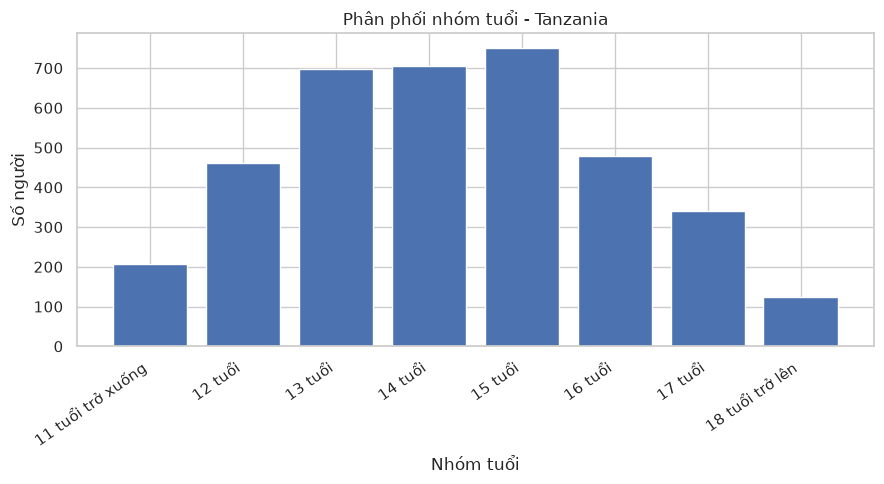

In [16]:
# Biểu đồ độ tuổi
plt.figure(figsize=(9, 5))
age_plot = eda["Q1"].map(age_labels).value_counts()
age_plot = age_plot.reindex(age_labels.values()).dropna()

plt.bar(age_plot.index, age_plot.values)
plt.title("Phân phối nhóm tuổi - Tanzania")
plt.xlabel("Nhóm tuổi")
plt.ylabel("Số người")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Nhận xét:
- Nhóm 15 tuổi là nhóm tuổi có số lượng lớn nhất trong codebook Tanzania.
- Nhóm từ 18 tuổi trở lên là nhóm nhỏ nhất trong codebook.
- Tỷ lệ trong biểu đồ được tính từ câu trả lời Q1 hợp lệ của CSV; xem bảng kết quả ở trên để đối chiếu.

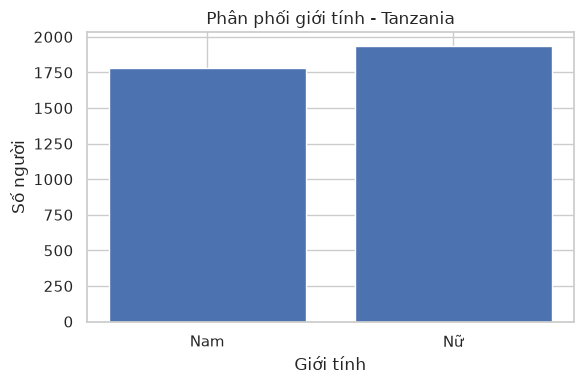

In [17]:
gender_plot = (
    eda["Q2"]
    .map(gender_labels)
    .value_counts()
    .reindex(["Nam", "Nữ"])
)

plt.figure(figsize=(6, 4))
plt.bar(gender_plot.index, gender_plot.values)
plt.title("Phân phối giới tính - Tanzania")
plt.xlabel("Giới tính")
plt.ylabel("Số người")
plt.tight_layout()
plt.show()

Nhận xét:
- Theo codebook, mẫu có 1.782 nam (47,9%) và 1.935 nữ (52,1%) trong các câu trả lời Q2 hợp lệ.
- Tỷ lệ trên được mô tả theo số câu trả lời hợp lệ, không áp dụng trọng số khảo sát.

In [18]:
#Phân tích cô đơn, lo lắng và số bạn thân

def make_distribution_table(series):
    counts = series.value_counts().sort_index()
    table = pd.DataFrame({
        "Số lượng": counts,
        "Tỷ lệ (%)": (
            counts / counts.sum() * 100
        ).round(2)
    })
    return table

for question in ["Q22", "Q23", "Q27"]:
    print(f"\nPhân phối {question}:")
    display(make_distribution_table(eda[question]))


Phân phối Q22:


,Số lượng,Tỷ lệ (%)
Q22,,
1.0,2145,57.29
2.0,883,23.58
3.0,440,11.75
4.0,215,5.74
5.0,61,1.63



Phân phối Q23:


,Số lượng,Tỷ lệ (%)
Q23,,
1.0,2250,60.37
2.0,807,21.65
3.0,440,11.81
4.0,179,4.80
5.0,51,1.37



Phân phối Q27:


,Số lượng,Tỷ lệ (%)
Q27,,
1.0,372,9.93
2.0,617,16.48
3.0,804,21.47
4.0,1952,52.12


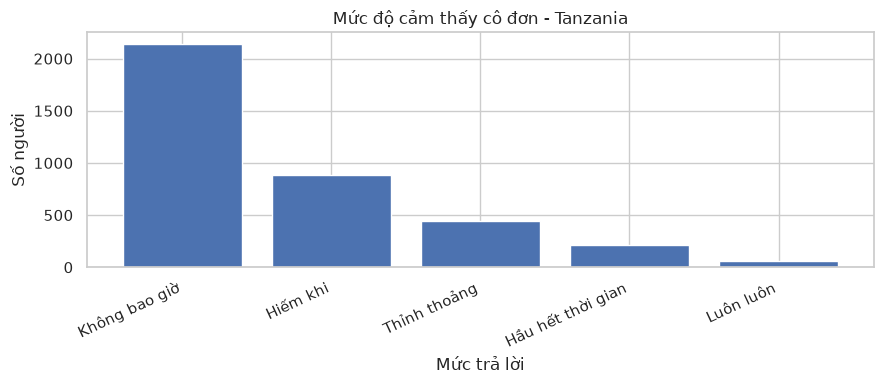

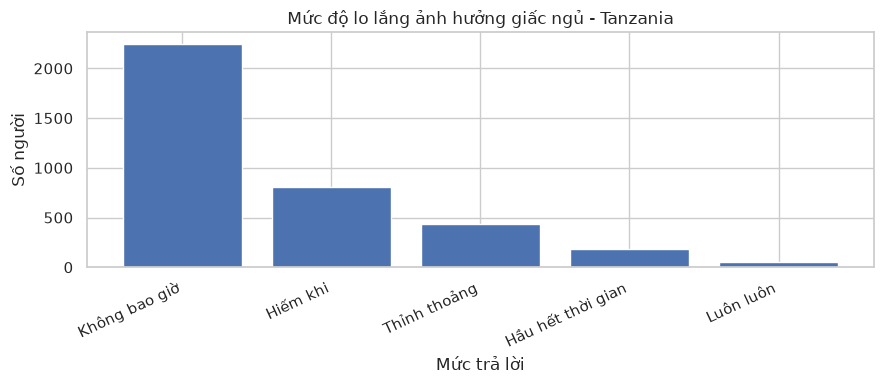

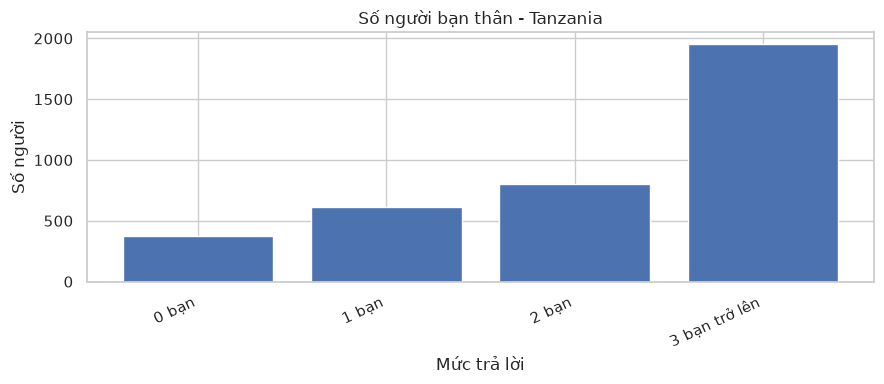

In [19]:
mental_labels = {
    "Q22": {
        1: "Không bao giờ",
        2: "Hiếm khi",
        3: "Thỉnh thoảng",
        4: "Hầu hết thời gian",
        5: "Luôn luôn"
    },
    "Q23": {
        1: "Không bao giờ",
        2: "Hiếm khi",
        3: "Thỉnh thoảng",
        4: "Hầu hết thời gian",
        5: "Luôn luôn"
    },
    "Q27": {
        1: "0 bạn",
        2: "1 bạn",
        3: "2 bạn",
        4: "3 bạn trở lên"
    }
}

plot_titles = {
    "Q22": "Mức độ cảm thấy cô đơn - Tanzania",
    "Q23": "Mức độ lo lắng ảnh hưởng giấc ngủ - Tanzania",
    "Q27": "Số người bạn thân - Tanzania"
}
for question in ["Q22", "Q23", "Q27"]:
    labels = mental_labels[question]
    counts = eda[question].value_counts().sort_index()
    x_labels = [
        labels.get(code, f"Mã {code}")
        for code in counts.index
    ]
    plt.figure(figsize=(9,4))
    plt.bar(x_labels, counts.values)
    plt.title(plot_titles[question])
    plt.xlabel("Mức trả lời")
    plt.ylabel("Số người")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

Nhận xét:
- Với Q22 và Q23, mã 1 là “Không bao giờ”; các mã cao hơn thể hiện tần suất thường xuyên hơn.
- Q27 mã 4 là “3 bạn trở lên”.
- Diễn giải số liệu dựa trên phân phối mã trả lời trong các bảng và biểu đồ phía trên.

In [20]:
 #Phân tích biến mục tiêu Q24
Q24_LABELS = {
    1: "Có",
    2: "Không"
}

# Chỉ thống kê các câu trả lời Q24 hợp lệ
q24_valid = eda["Q24"].isin([1,2])
q24 = eda.loc[q24_valid, "Q24"]

print("Tổng số dòng trong CSV:", len(eda))
print("Số câu trả lời Q24 hợp lệ:", int(q24_valid.sum()))
print("Số câu trả lời Q24 thiếu hoặc không hợp lệ:", int((~q24_valid).sum()))

q24_counts = q24.map(Q24_LABELS).value_counts()
q24_counts = q24_counts.reindex(["Có", "Không"], fill_value=0)

q24_table = pd.DataFrame({
    "Số lượng": q24_counts,
    "Tỷ lệ": (
        q24_counts / q24_counts.sum() * 100
    ).round(2)
})

print("\n Phân phối biến mục tiêu Q24:")
display(q24_table)

Tổng số dòng trong CSV: 3793
Số câu trả lời Q24 hợp lệ: 3677
Số câu trả lời Q24 thiếu hoặc không hợp lệ: 116

 Phân phối biến mục tiêu Q24:


,Số lượng,Tỷ lệ
Q24,,
Có,500,13.6
Không,3177,86.4


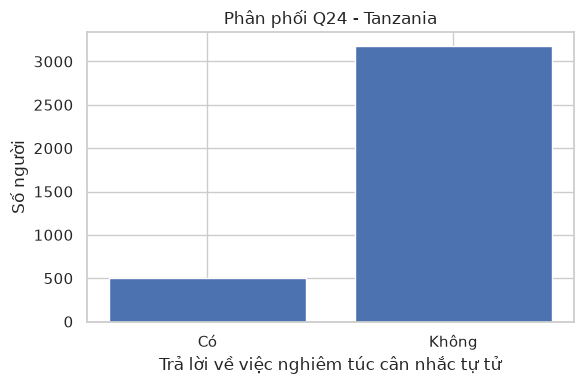

In [21]:
# Vẽ biểu đồ q24

plt.figure(figsize=(6,4))
plt.bar(
    q24_counts.index,
    q24_counts.values
)

plt.title("Phân phối Q24 - Tanzania")
plt.xlabel("Trả lời về việc nghiêm túc cân nhắc tự tử")
plt.ylabel("Số người")
plt.tight_layout()
plt.show()

In [22]:
# Kiểm tra mối liên hệ ban đầu với q24

eda_q24 = eda.loc[
    eda["Q24"].isin([1, 2])
].copy()

eda_q24["Q24_label"] = eda_q24["Q24"].map({
    1: "Có",
    2: "Không"
})

eda_q24["Q1_label"] = eda_q24["Q1"].map(age_labels)
eda_q24["Q2_label"] = eda_q24["Q2"].map(gender_labels)

# Thống kê Q24 theo nhóm tuổi
age_suicide_rate = (
    eda_q24.groupby("Q1")
    .agg(
        **{
            "Số trả lời Có": ("Q24", lambda s: (s == 1).sum()),
            "Tổng trả lời hợp lệ Q24": ("Q24", "count"),
        }
    )
    .reset_index()
)

# Tổng số người trong từng nhóm tuổi (Q1 hợp lệ)
age_suicide_rate["Tổng số người trong nhóm tuổi"] = (
    eda.groupby("Q1")["Q1"].count()
    .reindex(age_suicide_rate["Q1"])
    .to_numpy()
)

# Nhãn nhóm tuổi
age_suicide_rate["Nhóm tuổi"] = (
    age_suicide_rate["Q1"].map(age_labels)
)

# Tỷ lệ trả lời Có trên số câu trả lời Q24 hợp lệ
age_suicide_rate["Tỷ lệ Q24 = Có (%)"] = (
    age_suicide_rate["Số trả lời Có"]
    / age_suicide_rate["Tổng trả lời hợp lệ Q24"] * 100
)

# Hiển thị bảng
display(
    age_suicide_rate[
        [
            "Nhóm tuổi",
            "Tổng số người trong nhóm tuổi",
            "Số trả lời Có",
            "Tổng trả lời hợp lệ Q24",
            "Tỷ lệ Q24 = Có (%)"
        ]
    ].round(2)
)
# Thống kê Q24 theo giới tính
gender_suicide_rate = (
    eda_q24.groupby("Q2")
        .agg(
            **{
                "Số trả lời Có": ("Q24", lambda s: (s == 1).sum()),
                "Tổng trả lời hợp lệ Q24": ("Q24", "count"),
            }
        )
        .reset_index()
)
# Tổng số người thuộc giới tính nam / nữ (Q1 hợp lệ)
gender_suicide_rate["Tổng số người theo giới tính"] = (
    eda.groupby("Q2")["Q2"].count()
    .reindex(gender_suicide_rate["Q2"])
    .to_numpy()
)
# Đổi mã giới tính thành nhãn
gender_suicide_rate["Giới tính"] = (
    gender_suicide_rate["Q2"].map(gender_labels)
)
# Tỷ lệ trả lời Có trên số câu trả lời Q24 hợp lệ
gender_suicide_rate["Tỷ lệ Q24 = Có (%)"] = (
    gender_suicide_rate["Số trả lời Có"]
    / gender_suicide_rate["Tổng trả lời hợp lệ Q24"] * 100
)

# Hiển thị bảng
display(
   gender_suicide_rate[
           [
               "Giới tính",
               "Tổng số người theo giới tính",
               "Số trả lời Có",
               "Tổng trả lời hợp lệ Q24",
               "Tỷ lệ Q24 = Có (%)"
           ]
       ].round(2)
)

,Nhóm tuổi,Tổng số người trong nhóm tuổi,Số trả lời Có,Tổng trả lời hợp lệ Q24,Tỷ lệ Q24 = Có (%)
0,11 tuổi trở xuống,206,61,191,31.94
1,12 tuổi,461,70,448,15.62
2,13 tuổi,699,85,677,12.56
3,14 tuổi,705,86,689,12.48
4,15 tuổi,750,83,728,11.40
5,16 tuổi,478,48,466,10.30
6,17 tuổi,341,49,332,14.76
7,18 tuổi trở lên,125,13,123,10.57


,Giới tính,Tổng số người theo giới tính,Số trả lời Có,Tổng trả lời hợp lệ Q24,Tỷ lệ Q24 = Có (%)
0,Nam,1782,246,1730,14.22
1,Nữ,1935,239,1886,12.67


Tỷ lệ Q24 trả lời “Có” được so sánh giữa các nhóm tuổi và giới tính dựa trên các câu trả lời Q24 hợp lệ. Các nhóm có tuổi hoặc giới tính bị thiếu không được đưa vào so sánh tương ứng. Hãy căn cứ vào bảng kết quả đã chạy ở trên; khác biệt quan sát được chỉ mang tính mô tả và không chứng minh quan hệ nhân quả.

# PHẦN 6. TIỀN XỬ LÝ DỮ LIỆU CHO MACHINE LEARNING

Mục tiêu:
- Chọn các biến đầu vào và biến mục tiêu.
- Kiểm tra giá trị thiếu và mã dữ liệu.
- Xử lý dữ liệu trước khi huấn luyện mô hình.
- Tránh sử dụng các biến gây rò rỉ thông tin mục tiêu.

In [23]:
# Chọn biến đầu vào và biến mục tiêu

FEATURES = ["Q1", "Q2", "Q15", "Q16", "Q17", "Q22", "Q23", "Q27"]
TARGET = "Q24"

#Tạo bản dữ liệu riêng cho Machine Learning
ml_data = eda[FEATURES + [TARGET]].copy()
print("Kích thước dữ liệu ban đầu:", ml_data.shape)
print("\n Số giá trị thiếu theo từng biến:")
display(ml_data.isna().sum().to_frame("Số giá trị thiếu"))
print("\n Phân phối biến mục tiêu Q24:")
display(ml_data[TARGET].value_counts(dropna=False).sort_index())

Kích thước dữ liệu ban đầu: (3793, 9)

 Số giá trị thiếu theo từng biến:


,Số giá trị thiếu
Q1,28
Q2,76
Q15,44
Q16,63
Q17,620
Q22,49
Q23,66
Q27,48
Q24,116



 Phân phối biến mục tiêu Q24:


Q24
1.0     500
2.0    3177
NaN     116
Name: count, dtype: int64

In [24]:
ml_clean = ml_data.copy()

#1. Chỉ giữ các dòng có Q24 hợp lệ: 1 = Có, 2 = Không
ml_clean = ml_clean.loc[
    ml_clean["Q24"].isin([1, 2])
].copy()

print("Kích thước sau khi loại Q24 thiếu", ml_clean.shape)

#2. Kiểm tra giá trị thiếu trong các biến đầu vào
print("\n Giá trị thiếu của các biến đầu vào:")
display(
    ml_clean[FEATURES]
    .isna()
    .sum()
    .to_frame("Số giá trị thiếu")
)
#3. Kiểm tra phân phối mục tiêu sau khi lọc
print("\n Phân phối Q24 sau khi lọc:")
display(ml_clean["Q24"].value_counts().sort_index())

Kích thước sau khi loại Q24 thiếu (3677, 9)

 Giá trị thiếu của các biến đầu vào:


,Số giá trị thiếu
Q1,23
Q2,61
Q15,37
Q16,53
Q17,585
Q22,34
Q23,50
Q27,34



 Phân phối Q24 sau khi lọc:


Q24
1.0     500
2.0    3177
Name: count, dtype: int64

In [25]:
# Điền giá trị thiếu ở các biến đầu vào
ml_imputed = ml_clean.copy()

for col in FEATURES:
    if ml_imputed[col].isna().any():
        mode_value = ml_imputed[col].mode(dropna=True)[0]
        ml_imputed[col] = ml_imputed[col].fillna(mode_value)

print("Kích thước sau khi xử lý:", ml_imputed.shape)
print("\n Số giá trị thiếu còn lại:")
display(
    ml_imputed[FEATURES + [TARGET]]
    .isna()
    .sum()
    .to_frame("Số giá trị thiếu")
)
print("\n Phân phối Q24:")
display(ml_imputed[TARGET].value_counts().sort_index())

Kích thước sau khi xử lý: (3677, 9)

 Số giá trị thiếu còn lại:


,Số giá trị thiếu
Q1,0
Q2,0
Q15,0
Q16,0
Q17,0
Q22,0
Q23,0
Q27,0
Q24,0



 Phân phối Q24:


Q24
1.0     500
2.0    3177
Name: count, dtype: int64

In [26]:
# Tạo nhãn mục tiêu nhị phân
ml_model = ml_imputed.copy()
# Q24: 1 = Có -> 1; 2 = Không -> 0
ml_model["Q24"] = ml_model["Q24"].map({
    1: 1,
    2: 0
}).astype(int)

print("Phân phối nhãn Q24:")
display(
    ml_model["Q24"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Không (0)", 1:"Có (1)"})
    .to_frame("Số người")
)
print("\n Tỷ lệ từng nhãn (%):")
display(
    (
        ml_model["Q24"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .rename(index={0: "Không (0)", 1: "Có (1)"})
        .round(2)
        .to_frame("Tỷ lệ (%)")
    )
)

Phân phối nhãn Q24:


,Số người
Q24,
Không (0),3177
Có (1),500



 Tỷ lệ từng nhãn (%):


,Tỷ lệ (%)
Q24,
Không (0),86.4
Có (1),13.6


Chia dữ liệu thành tập huấn luyện và kiểm tra

In [27]:
from sklearn.model_selection import train_test_split
# x: các biến đầu vào,  y: biến mục tiêu
x = ml_model[FEATURES].copy()
y = ml_model["Q24"].copy()

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Kích thước x_train:", x_train.shape)
print("Kích thước x_test:", x_test.shape)
print("Kích thước y_train:", y_train.shape)
print("Kích thước y_test:", y_test.shape)

print("\n Tỷ lệ nhãn trong tập train (%):")
display((y_train.value_counts(normalize=True) * 100).round(2))
print("\n Tỷ lệ nhãn trong tập test (%):")
display((y_test.value_counts(normalize=True) * 100).round(2))

Kích thước x_train: (2941, 8)
Kích thước x_test: (736, 8)
Kích thước y_train: (2941,)
Kích thước y_test: (736,)

 Tỷ lệ nhãn trong tập train (%):


Q24
0    86.4
1    13.6
Name: proportion, dtype: float64


 Tỷ lệ nhãn trong tập test (%):


Q24
0    86.41
1    13.59
Name: proportion, dtype: float64

In [28]:
from sklearn.model_selection import train_test_split
# Tạo x và y từ dữ liệu chưa điền thiếu
x = ml_clean[FEATURES].copy()
# Q24: 1=Có, 2=Không
y = ml_clean["Q24"].map({1: 1, 2: 0}).astype(int)

# Chia train/test trước khi học giá trị điền thiếu
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("x_train:", x_train.shape)
print("x_test:", x_test.shape)
print("Giá trị thiếu trong x_train:", x_train.isna().sum().sum())
print("Giá trị thiếu trong x_test:", x_test.isna().sum().sum())

x_train: (2941, 8)
x_test: (736, 8)
Giá trị thiếu trong x_train: 707
Giá trị thiếu trong x_test: 170


## Chỉ số đánh giá mô hình 


- TN (True Negative) - Dự đoán âm tính đúng (dự đoán Không và thực tế cũng là Không)
- FP (False Positive)- Dự đoán dương tính sai (dự đoán Có và thực tế là Không)
- FN (False Negative)- Dự đoán âm tính sai (dự đoán Không và thực tế là Có)
- TP (True Positive) - Dự đoán dương tính đúng (dự đoán Có và thực tế cũng là Có)

- Accuracy - Độ chính xác tổng thể = $\frac{TP + TN}{TP + TN + FP + FN}$
- Precision - Độ chính xác của dự đoán Có = $\frac{TP}{TP + FP}$
- Recall - Khả năng nhận diện nhóm Có = $\frac{TP}{TP + FN}$
- F1-score - Chỉ số đánh giá mô hình Machine Learning = 2 x $\frac{Precision * Recall}{Precision + Recall}$
- ROC-AUC - Chỉ số đo lường khả năng phân biệt hai lớp của mô hình phân loại :


    - ROC-AUC là diện tích đường cong ROC(Receiver Operating Characteristic)

    - Đường ROC biểu diễn mối quan hệ giữa: 

        + TPR (True Positive Rate)- chính là Recall = $\frac{TP}{TP + FN}$


        + FPR(False Positive Rate)- tỷ lệ dự đoán nhầm nhóm Không thành Có = $\frac{FP}{FP + TN}$

    - ROC-AUC được tính bằng tích phân: $$AUC_{ROC} = \int_0^1 TPR(FPR) \, d(FPR)$$
- RP-AUC - Chỉ số đánh giá hiệu quả của mô hình phân loại:


    - PR-AUC(Precision-Recall Area Under the Curve) là diện tích dưới đường cong Precision-Recall
    $$AUC_{PR} = \int_0^1 Precision(Recall) \, d(Recall)$$



# Xây dựng mô hình Logistic Regression đầu tiên

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

model_results = {}

SimpleImputer(strategy="most_frequent"): điền giá trị thiếu bằng mã trả lời xuất hiện nhiều nhất, được tính từ tập train.



StandardScaler(): chuẩn hóa thang đo các biến đầu vào.



LogisticRegression(): học cách phân loại Q24 thành 0 = Không hoặc 1 = Có.



fit(x_train, y_train): chỉ huấn luyện trên tập train; tập test được giữ riêng để đánh giá.

In [30]:
# Pipeline: điền giá trị thiếu -> chuẩn hóa -> huấn luyện
logistic_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])
# Huấn luyện chỉ trên tập train
logistic_model.fit(x_train, y_train)
print("Đã huấn luyện Logistic Regression thành công!")

Đã huấn luyện Logistic Regression thành công!


In [31]:
# Dự đoán trên tập test
y_pred = logistic_model.predict(x_test)
print("Số dự đoán:", len(y_pred))
print("10 nhãn thực tế đầu tiên:", y_test.iloc[:10].tolist())
print("10 nhãn dự đoán đầu tiên:", y_pred[:10].tolist())

Số dự đoán: 736
10 nhãn thực tế đầu tiên: [1, 0, 0, 0, 0, 0, 0, 0, 0, 0]
10 nhãn dự đoán đầu tiên: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


# Đánh giá mô hình Logistic Regression

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_auc_score

)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


#Bảng báo cáo phân loại
report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Không (0)", "Có (1)"],
    zero_division=0,
    output_dict=True
)

df_report = pd.DataFrame(report).transpose()

display(df_report.style
        .format("{:.4f}", subset=["precision", "recall", "f1-score"])
        .set_caption("BÁO CÁO PHÂN LOẠI - LOGISTIC REGRESSION")
        .set_properties(**{"text-align": "center"})
        .set_table_styles([
            {"selector": "caption",
             "props": [("font-size", "16px"),
                       ("font-weight", "bold"),
                       ("text-align", "center")]},
            {"selector": "th",
             "props": [("text-align", "center"),
                       ("background-color", "#050D13")]}
        ]))

,precision,recall,f1-score,support
Không (0),0.8639,0.9984,0.9263,636.000000
Có (1),0.0000,0.0000,0.0000,100.000000
accuracy,0.8628,0.8628,0.8628,0.862772
macro avg,0.4320,0.4992,0.4632,736.000000
weighted avg,0.7466,0.8628,0.8005,736.000000


Nhận xét:
- Đọc Precision, Recall và F1-score riêng cho lớp “Có (1)”; Accuracy cao có thể gây hiểu nhầm khi lớp “Không” chiếm đa số.
- So sánh số lượng TP/FN trong ma trận nhầm lẫn để đánh giá số trường hợp Q24 “Có” được nhận diện hoặc bỏ sót.
- Đây là kết quả trên một tập test của khảo sát, không phải đánh giá năng lực chẩn đoán.

In [33]:
# Xác suất dự đoán thuộc nhóm Có (Q24 = 1)
y_prob = logistic_model.predict_proba(x_test)[:, 1]
# Tính các chỉ số đánh giá
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "PR-AUC (Average Precision)": average_precision_score(y_test, y_prob)
}
print("LOGISTIC REGRESSION")
metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Chỉ số", "Giá trị"]
)
display(metrics_df.round(4))
model_results["Logistic Regression"] = metrics


LOGISTIC REGRESSION


,Chỉ số,Giá trị
0,Accuracy,0.8628
1,Precision,0.0000
2,Recall,0.0000
3,F1-score,0.0000
4,ROC-AUC,0.6117
5,PR-AUC (Average Precision),0.2016


Nhận xét:
- Accuracy là tỷ lệ dự đoán đúng trên toàn bộ tập test.
- Precision cho biết trong các dự đoán “Có”, tỷ lệ thực tế trả lời “Có”.
- Recall cho biết tỷ lệ các câu trả lời “Có” thực tế được mô hình nhận diện.
- F1-score cân bằng Precision và Recall; ROC-AUC/PR-AUC đánh giá thứ hạng xác suất dự đoán.
- Dùng các giá trị hiển thị trong bảng phía trên; không suy diễn kết quả khảo sát thành quan hệ nhân quả.

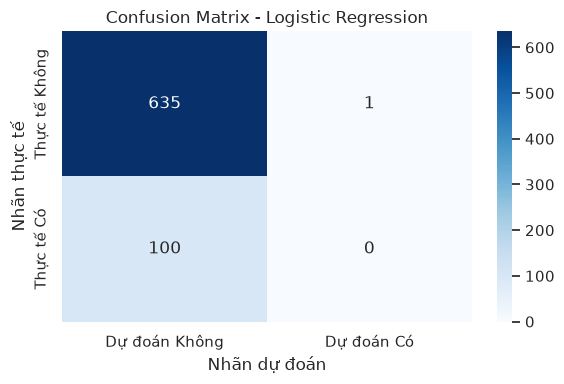

              precision    recall  f1-score   support

   Không (0)       0.86      1.00      0.93       636
      Có (1)       0.00      0.00      0.00       100

    accuracy                           0.86       736
   macro avg       0.43      0.50      0.46       736
weighted avg       0.75      0.86      0.80       736



In [34]:
# Vẽ ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Dự đoán Không", "Dự đoán Có"],
    yticklabels=["Thực tế Không", "Thực tế Có"],
)

plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Không (0)", "Có (1)"],
    zero_division=0
))

Ma trận nhầm lẫn ở ô phía trên cho biết số dự đoán đúng/sai của Logistic Regression trên tập test:
- TN: dự đoán “Không” và thực tế “Không”.
- FP: dự đoán “Có” nhưng thực tế “Không”.
- FN: dự đoán “Không” nhưng thực tế “Có”.
- TP: dự đoán “Có” và thực tế “Có”.

## Điều chỉnh ngưỡng dự đoán

In [35]:
#Điều chỉnh ngưỡng dự đoán
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd
# Xác suất dự đoán Q24 = Có
y_proba = logistic_model.predict_proba(x_test)[:, 1]
thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]
threshold_results = []

for threshold in thresholds:
    pred = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()
    threshold_results.append({
        "Ngưỡng": threshold,
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred, zero_division=0
        ),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })
threshold_df = pd.DataFrame(threshold_results)
display(
    threshold_df.round(3)
)

,Ngưỡng,Precision,Recall,F1-score,TN,FP,FN,TP
0,0.5,0.000,0.00,0.000,635,1,100,0
1,0.4,0.333,0.01,0.019,634,2,99,1
2,0.3,0.250,0.04,0.069,624,12,96,4
3,0.2,0.282,0.20,0.234,585,51,80,20
4,0.1,0.164,0.81,0.273,223,413,19,81


Khi giảm ngưỡng dự đoán, Recall thường tăng nhưng Precision có thể giảm; khi tăng ngưỡng, xu hướng thường ngược lại. Dùng bảng ngưỡng ở trên để chọn lựa theo mục tiêu, không mặc định một ngưỡng là tốt nhất cho mọi trường hợp.

## Huấn luyện mô hình Decision Tree

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier

#Xây dựng mô hình Decision Tree
tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42
    ))
])
#Huấn luyện
tree_model.fit(x_train, y_train)
# Dự đoán
tree_pred = tree_model.predict(x_test)
tree_proba = tree_model.predict_proba(x_test)[:, 1]
print("Đã huấn luyện Decision Tree thành công!")

Đã huấn luyện Decision Tree thành công!


In [37]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    classification_report
)

report = classification_report(
    y_test,
    tree_pred,
    labels=[0,1],
    target_names=["Không (0)", "Có (1)"],
    zero_division=0,
    output_dict=True
)

tree_report = pd.DataFrame(report).transpose()
display(tree_report.style
        .format("{:4f}", subset=["precision", "recall", "f1-score"])
        .set_caption("BÁO CÁO PHÂN LOẠI - DECISION TREE")
        .set_properties(**{"text-align":"center"})
        .set_table_styles([
            {"selector": "caption",
             "props": [("font-size", "16px"),
                       ("font-weight", "bold"),
                       ("text-align", "center")]},
            {"selector": "th",
             "props": [("text-align", "center"),
                       ("background-color", "#050D13")]}
        ]))

,precision,recall,f1-score,support
Không (0),0.889423,0.581761,0.703422,636.000000
Có (1),0.168750,0.540000,0.257143,100.000000
accuracy,0.576087,0.576087,0.576087,0.576087
macro avg,0.529087,0.560881,0.480282,736.000000
weighted avg,0.791506,0.576087,0.642786,736.000000


Nhận xét:
- Đối chiếu Accuracy và các chỉ số của lớp “Có (1)” trong bảng báo cáo Decision Tree.
- Cây quyết định có thể nhận diện thêm ca “Có” nhưng cũng có thể tăng dự đoán nhầm.
- Không kết luận chỉ từ Accuracy; xem cả Recall, Precision, F1-score và ma trận nhầm lẫn.

In [38]:
# Xác suất dự đoán thuộc nhóm Có (Q24 = 1)
tree_proba = tree_model.predict_proba(x_test)[:, 1]
# Tính các chỉ số đánh giá
metrics = {
    "Accuracy": accuracy_score(y_test, tree_pred),
    "Precision": precision_score(y_test, tree_pred, zero_division=0),
    "Recall": recall_score(y_test, tree_pred, zero_division=0),
    "F1-score": f1_score(y_test, tree_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, tree_proba),
    "PR-AUC (Average Precision)": average_precision_score(y_test, tree_proba)
}
print("DECISION TREE")
metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Chỉ số", "Giá trị"]
)
display(metrics_df.round(4))

model_results["Decision Tree"] = metrics


DECISION TREE


,Chỉ số,Giá trị
0,Accuracy,0.5761
1,Precision,0.1688
2,Recall,0.5400
3,F1-score,0.2571
4,ROC-AUC,0.5885
5,PR-AUC (Average Precision),0.2152


Dùng các chỉ số Decision Tree hiển thị ở bảng phía trên để đánh giá Accuracy, Precision, Recall, F1-score, ROC-AUC và PR-AUC. PR-AUC cần được so sánh với tỷ lệ lớp “Có” trong tập test; kết quả chỉ có ý nghĩa trong lần chia train/test này.

## Huấn luyện mô hình Random Forest


In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

#Xây dựng mô hình Random Forest
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

#Huấn luyện trên tập train
rf_model.fit(x_train, y_train)
#Dự đoán trên tập test
rf_pred = rf_model.predict(x_test)
rf_proba = rf_model.predict_proba(x_test)[:, 1]
print("Đã huấn luyện Random Forest thành công!")

Đã huấn luyện Random Forest thành công!


In [40]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    classification_report
)


report = classification_report(
    y_test,
    rf_pred,
    labels=[0, 1],
    target_names=["Không (0)", "Có (1)"],
    zero_division=0,
    output_dict=True
)

rf_report = pd.DataFrame(report).transpose()

display(rf_report.style
        .format("{:.4f}", subset=["precision", "recall", "f1-score"])
        .set_caption("BÁO CÁO PHÂN LOẠI - RANDOM FOREST")
        .set_properties(**{"text-align": "center"})
        .set_table_styles([
            {"selector": "caption",
             "props": [("font-size", "16px"),
                       ("font-weight", "bold"),
                       ("text-align", "center")]},
            {"selector": "th",
             "props": [("text-align", "center"),
                       ("background-color", "#050D13")]}
        ]))


,precision,recall,f1-score,support
Không (0),0.8972,0.7138,0.7951,636.000000
Có (1),0.2087,0.4800,0.2909,100.000000
accuracy,0.6821,0.6821,0.6821,0.682065
macro avg,0.5530,0.5969,0.5430,736.000000
weighted avg,0.8037,0.6821,0.7266,736.000000


Nhận xét:
- Đối chiếu Precision, Recall và F1-score của Random Forest với các mô hình khác.
- Nếu Recall cao hơn, mô hình nhận diện được nhiều câu trả lời “Có” hơn nhưng có thể tạo thêm dương tính giả.
- Các số liệu hiển thị là kết quả mẫu; chưa hiệu chỉnh theo thiết kế khảo sát.

In [41]:
# Xác suất dự đoán thuộc nhóm Có (Q24 = 1)
rf_proba = rf_model.predict_proba(x_test)[:, 1]
# Tính các chỉ số đánh giá
metrics = {
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred, zero_division=0),
    "Recall": recall_score(y_test, rf_pred, zero_division=0),
    "F1-score": f1_score(y_test, rf_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, rf_proba),
    "PR-AUC (Average Precision)": average_precision_score(y_test, rf_proba)
}
print("RANDOM FOREST")
metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Chỉ số", "Giá trị"]
)
display(metrics_df.round(4))

model_results["Random Forest"] = metrics


RANDOM FOREST


,Chỉ số,Giá trị
0,Accuracy,0.6821
1,Precision,0.2087
2,Recall,0.4800
3,F1-score,0.2909
4,ROC-AUC,0.5881
5,PR-AUC (Average Precision),0.2312


Dựa vào bảng đánh giá Random Forest phía trên để xem Accuracy, Precision, Recall, F1-score, ROC-AUC và PR-AUC. Ưu tiên chỉ số phù hợp với mục tiêu phân tích thay vì mặc định mô hình này tốt nhất.

## Huấn luyện mô hình Gradient Boosting

In [42]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier

gb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(x_train, y_train)

gb_pred = gb_model.predict(x_test)
gb_proba = gb_model.predict_proba(x_test)[:, 1]

print("Đã huấn luyện Gradient Boosting thành công!")

Đã huấn luyện Gradient Boosting thành công!


In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

#Bảng báo cáo phân loại
report = classification_report(
    y_test,
    gb_pred,
    labels=[0, 1],
    target_names=["Không (0)", "Có (1)"],
    zero_division=0,
    output_dict=True
)

gb_report = pd.DataFrame(report).transpose()

display(gb_report.style
        .format("{:.4f}", subset=["precision", "recall", "f1-score"])
        .set_caption("BÁO CÁO PHÂN LOẠI - GRADIENT BOOSTING")
        .set_properties(**{"text-align": "center"})
        .set_table_styles([
            {"selector": "caption",
             "props": [("font-size", "16px"),
                       ("font-weight", "bold"),
                       ("text-align", "center")]},
            {"selector": "th",
             "props": [("text-align", "center"),
                       ("background-color", "#050D13")]}
        ]))


,precision,recall,f1-score,support
Không (0),0.8693,0.9937,0.9274,636.000000
Có (1),0.5556,0.0500,0.0917,100.000000
accuracy,0.8655,0.8655,0.8655,0.865489
macro avg,0.7124,0.5219,0.5096,736.000000
weighted avg,0.8267,0.8655,0.8138,736.000000


Nhận xét:
- Gradient Boosting có thể đạt Accuracy cao trong khi Recall của lớp “Có” còn thấp do mất cân bằng lớp.
- Hãy so sánh các chỉ số của lớp “Có” và ma trận nhầm lẫn, không chỉ dựa vào độ chính xác tổng thể.

In [44]:
# Xác suất dự đoán thuộc nhóm Có (Q24 = 1)
gb_proba = gb_model.predict_proba(x_test)[:, 1]
# Tính các chỉ số đánh giá
metrics = {
    "Accuracy": accuracy_score(y_test, gb_pred),
    "Precision": precision_score(y_test, gb_pred, zero_division=0),
    "Recall": recall_score(y_test, gb_pred, zero_division=0),
    "F1-score": f1_score(y_test, gb_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, gb_proba),
    "PR-AUC (Average Precision)": average_precision_score(y_test, gb_proba)
}
print("GRADIENT BOOSTING")
metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Chỉ số", "Giá trị"]
)
display(metrics_df.round(4))


model_results["Gradient Boosting"] = metrics


GRADIENT BOOSTING


,Chỉ số,Giá trị
0,Accuracy,0.8655
1,Precision,0.5556
2,Recall,0.0500
3,F1-score,0.0917
4,ROC-AUC,0.5813
5,PR-AUC (Average Precision),0.2161


Bảng phía trên trình bày các chỉ số của Gradient Boosting trên tập test. Diễn giải Precision/Recall/F1-score của lớp “Có” cùng ROC-AUC và PR-AUC; so sánh PR-AUC với tỷ lệ cơ sở của lớp dương.

## Deep Learning bằng mạng nơ-ron nhân tạo Neural Network (MLP)

Sử dụng MLPClassifier của scikit-learn để thử mô hình mạng nơ-ron trên cùng cách chia train/test.

In [45]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Fit imputer and scaler on train only, then transform the test set.
imputer = SimpleImputer(strategy="most_frequent")
x_train_dl = imputer.fit_transform(x_train)
x_test_dl = imputer.transform(x_test)
scaler = StandardScaler()
x_train_dl = scaler.fit_transform(x_train_dl)
x_test_dl = scaler.transform(x_test_dl)
print("x_train:", x_train_dl.shape)
print("x_test:", x_test_dl.shape)
print("Chuẩn bị dữ liệu Neural Network thành công!")

x_train: (2941, 8)
x_test: (736, 8)
Chuẩn bị dữ liệu Neural Network thành công!


In [46]:
from sklearn.neural_network import MLPClassifier

nn_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    early_stopping=True,
    max_iter=300,
    random_state=42,
)
print(nn_model)

MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), max_iter=300,
              random_state=42)


Huấn luyện mô hình

In [47]:
history = nn_model.fit(
    x_train_dl,
    y_train,
)
print("Đã huấn luyện Neural Network (MLP) thành công!")

Đã huấn luyện Neural Network (MLP) thành công!


In [48]:
# Xác suất dự đoán thuộc nhóm Có (Q24 = 1)
nn_proba = nn_model.predict_proba(x_test_dl)[:, 1]
nn_pred = (nn_proba >= 0.5).astype(int)
print("Số mẫu kiểm tra:", len(nn_pred))

Số mẫu kiểm tra: 736


In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)


#Bảng báo cáo phân loại
report = classification_report(
    y_test,
    nn_pred,
    labels=[0, 1],
    target_names=["Không (0)", "Có (1)"],
    zero_division=0,
    output_dict=True
)

nn_report = pd.DataFrame(report).transpose()

display(nn_report.style
        .format("{:.4f}", subset=["precision", "recall", "f1-score"])
        .set_caption("BÁO CÁO PHÂN LOẠI - NEURAL NETWORK")
        .set_properties(**{"text-align": "center"})
        .set_table_styles([
            {"selector": "caption",
             "props": [("font-size", "16px"),
                       ("font-weight", "bold"),
                       ("text-align", "center")]},
            {"selector": "th",
             "props": [("text-align", "center"),
                       ("background-color", "#050D13")]}
        ]))


,precision,recall,f1-score,support
Không (0),0.8641,1.0000,0.9271,636.000000
Có (1),0.0000,0.0000,0.0000,100.000000
accuracy,0.8641,0.8641,0.8641,0.864130
macro avg,0.4321,0.5000,0.4636,736.000000
weighted avg,0.7467,0.8641,0.8011,736.000000


Nhận xét:
- Đánh giá Neural Network theo các chỉ số ở bảng báo cáo; đặc biệt kiểm tra Recall và F1-score của lớp “Có”.
- Nếu mô hình hầu như chỉ dự đoán lớp “Không”, Accuracy vẫn có thể cao do mất cân bằng lớp.
- MLP là mô hình tham khảo trong bài tập, không phải công cụ lâm sàng.

In [50]:
# Xác suất dự đoán thuộc nhóm Có (Q24 = 1)
nn_proba = nn_model.predict_proba(x_test_dl)[:, 1]
# Chuyển xác suất thành nhãn 0 hoặc 1
nn_pred = (nn_proba >= 0.5).astype(int)
# Tính các chỉ số đánh giá
metrics = {
    "Accuracy": accuracy_score(y_test, nn_pred),
    "Precision": precision_score(y_test, nn_pred, zero_division=0),
    "Recall": recall_score(y_test, nn_pred, zero_division=0),
    "F1-score": f1_score(y_test, nn_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, nn_proba),
    "PR-AUC (Average Precision)": average_precision_score(y_test, nn_proba)
}
print("NEURAL NETWORK")
metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Chỉ số", "Giá trị"]
)
display(metrics_df.round(4))

model_results["Neural Network"] = metrics


NEURAL NETWORK


,Chỉ số,Giá trị
0,Accuracy,0.8641
1,Precision,0.0000
2,Recall,0.0000
3,F1-score,0.0000
4,ROC-AUC,0.4648
5,PR-AUC (Average Precision),0.1477


Các chỉ số Accuracy, Precision, Recall, F1-score, ROC-AUC và PR-AUC của MLP được hiển thị trong bảng phía trên. So sánh với các mô hình còn lại trên cùng tập test.

## TỔNG HỢP VÀ SO SÁNH 5 MÔ HÌNH MACHINE LEARNING VÀ DEEP LEARNING

In [51]:
# Tổng hợp chỉ số thực tế của 5 mô hình trong lần chạy hiện tại
comparison_data = []
for model_name, metrics in model_results.items():
    comparison_data.append({
        "Mô hình": model_name,
        "Accuracy": metrics["Accuracy"],
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "F1-score": metrics["F1-score"],
        "ROC-AUC": metrics["ROC-AUC"],
        "PR-AUC": metrics["PR-AUC (Average Precision)"],
    })
comparison_df = pd.DataFrame(comparison_data)
display(comparison_df.round(4))

,Mô hình,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8628,0.0000,0.00,0.0000,0.6117,0.2016
1,Decision Tree,0.5761,0.1688,0.54,0.2571,0.5885,0.2152
2,Random Forest,0.6821,0.2087,0.48,0.2909,0.5881,0.2312
3,Gradient Boosting,0.8655,0.5556,0.05,0.0917,0.5813,0.2161
4,Neural Network,0.8641,0.0000,0.00,0.0000,0.4648,0.1477


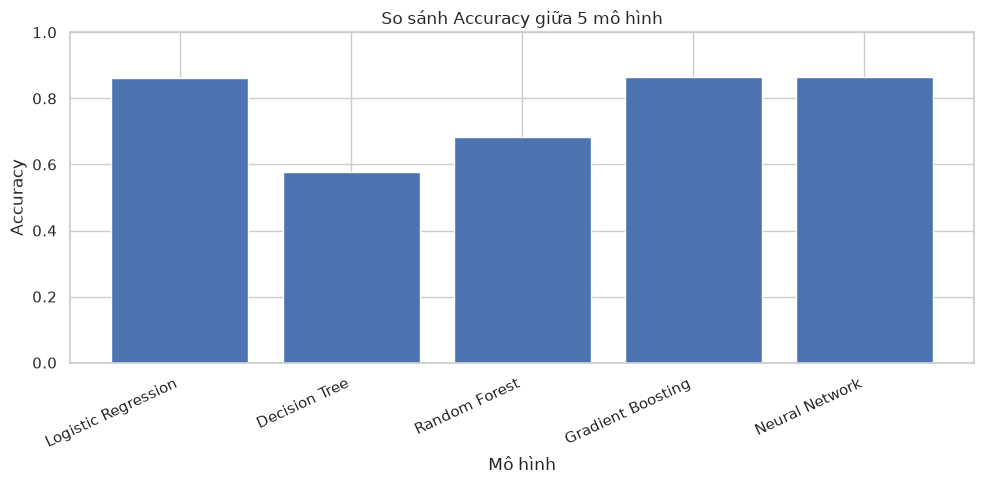

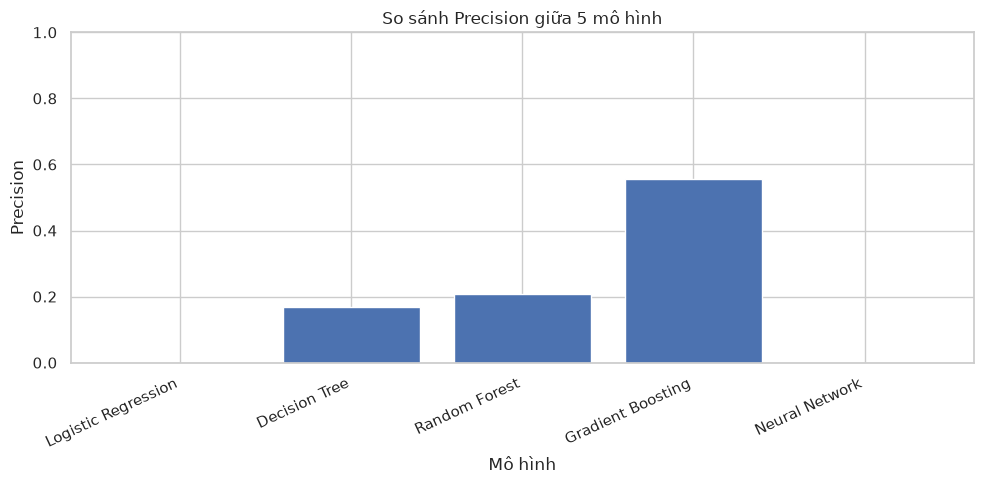

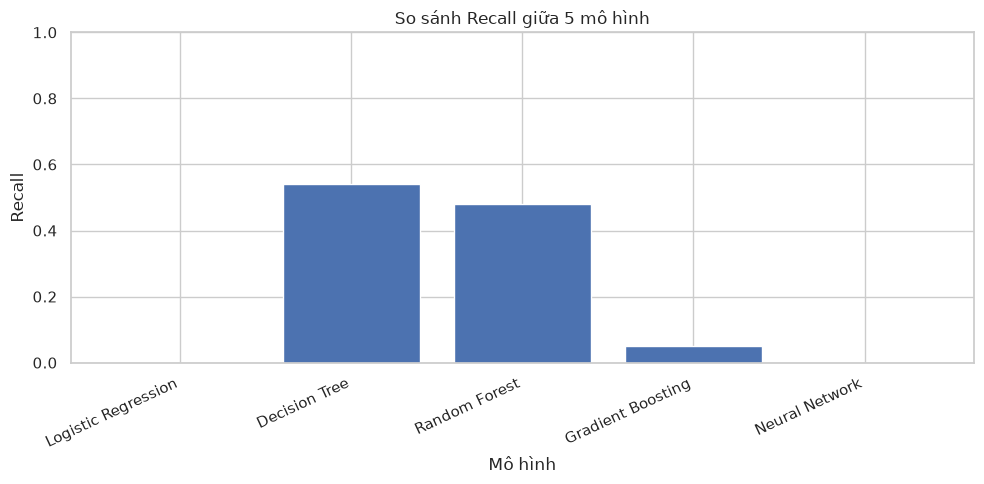

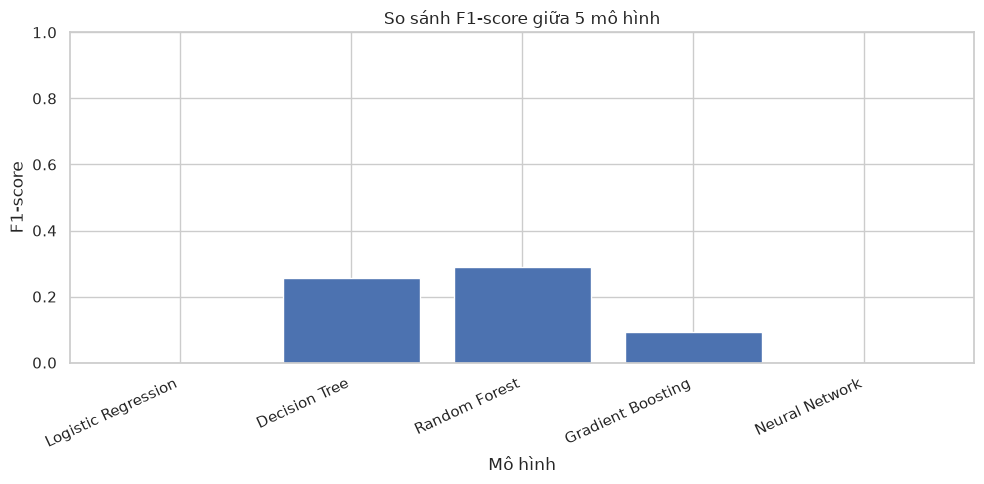

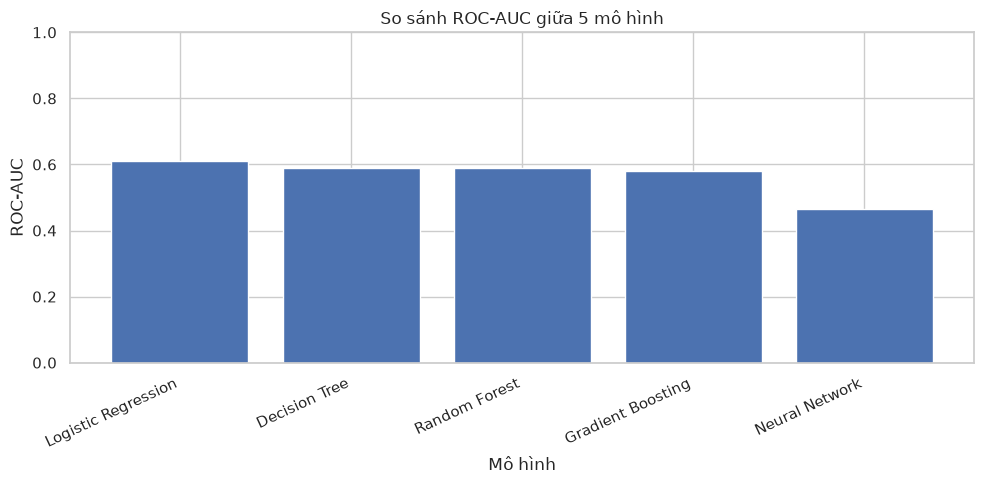

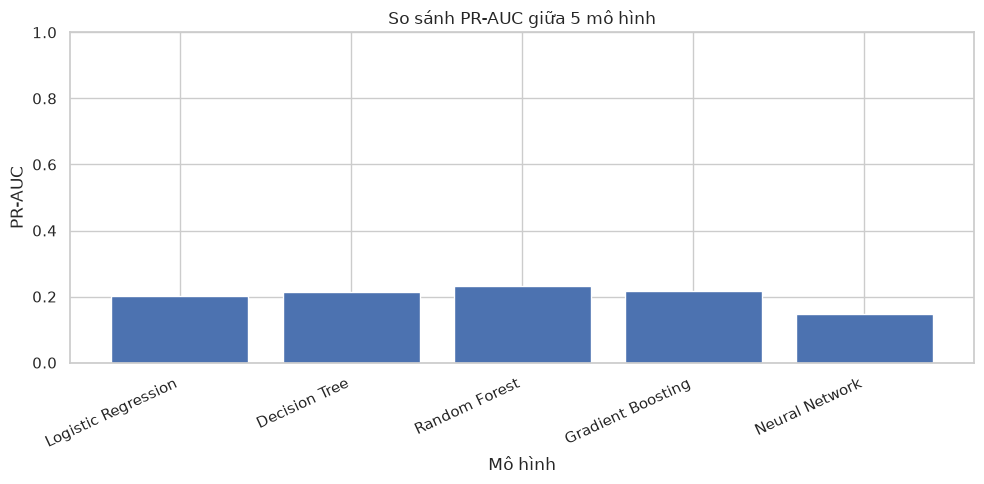

In [52]:
metrics_to_plot = [
    "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"
]

for metric in metrics_to_plot:
    plt.figure(figsize=(10, 5))
    plt.bar(
        comparison_df["Mô hình"],
        comparison_df[metric]
    )
    plt.title(f"So sánh {metric} giữa 5 mô hình")
    plt.xlabel("Mô hình")
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

In [53]:
for metric in metrics_to_plot:
    best_idx = comparison_df[metric].idxmax()

    print(
        f"{metric}: {comparison_df.loc[best_idx, 'Mô hình']}"
        f"({comparison_df.loc[best_idx, metric]:.4f})"
    )

Accuracy: Gradient Boosting(0.8655)
Precision: Gradient Boosting(0.5556)
Recall: Decision Tree(0.5400)
F1-score: Random Forest(0.2909)
ROC-AUC: Logistic Regression(0.6117)
PR-AUC: Random Forest(0.2312)


Nhận xét:
- Bảng và biểu đồ phía trên tổng hợp kết quả trên cùng tập test.
- Chọn mô hình theo mục tiêu phù hợp (ví dụ Recall/F1-score cho lớp “Có”), đồng thời xem Precision và ma trận nhầm lẫn.
- Chỉ số tốt hơn trong một lần chia dữ liệu không đảm bảo tổng quát hóa sang quần thể khác hoặc thời điểm khác.

## CẢI THIỆN MÔ HÌNH RANDOM FOREST

In [54]:
import numpy as np
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    accuracy_score, average_precision_score, roc_auc_score
)

# Lấy xác suất dự đoán nhóm Có (Q24 = 1)
rf_proba = rf_model.predict_proba(x_test)[:, 1]

print("Đã lấy xác suất dự đoán!")
print("5 xác suất đầu tiên:", rf_proba[:5])

Đã lấy xác suất dự đoán!
5 xác suất đầu tiên: [0.51200551 0.38425003 0.36101346 0.39935352 0.35316487]


In [55]:
#Thử nhiều ngưỡng dự đoán
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

threshold_results = []

for threshold in thresholds:
    rf_pred_threshold = (rf_proba >= threshold).astype(int)

    threshold_results.append({
        "Ngưỡng": threshold,
        "Accuracy": accuracy_score(y_test, rf_pred_threshold),
        "Precision": precision_score(
            y_test, rf_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, rf_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, rf_pred_threshold, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Ngưỡng,Accuracy,Precision,Recall,F1-score
0,0.2,0.1359,0.1359,1.00,0.2392
1,0.3,0.1617,0.1333,0.94,0.2335
2,0.4,0.4633,0.1463,0.61,0.2360
3,0.5,0.6821,0.2087,0.48,0.2909
4,0.6,0.8003,0.2169,0.18,0.1967


Vẽ biểu đồ so sánh


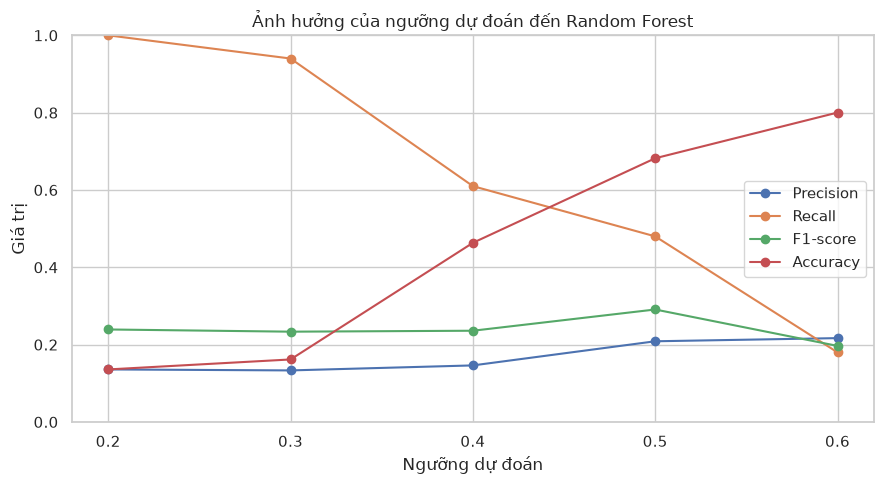

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for metric in ["Precision", "Recall", "F1-score", "Accuracy"]:
    plt.plot(
        threshold_df["Ngưỡng"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

plt.title("Ảnh hưởng của ngưỡng dự đoán đến Random Forest")
plt.xlabel("Ngưỡng dự đoán")
plt.ylabel("Giá trị")
plt.xticks(thresholds)
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Nhận xét kết quả điều chỉnh ngưỡng Random Forest:
- Ngưỡng thấp thường tăng Recall và số dương tính giả; ngưỡng cao thường giảm Recall.
- Chọn ngưỡng dựa trên sự đánh đổi thể hiện trong bảng và biểu đồ, không dựa trên một ngưỡng cố định.

Chọn ngưỡng cần gắn với mục tiêu và mức sai số chấp nhận được. Các kết quả này chỉ minh họa sự đánh đổi Precision–Recall trên tập test Tanzania 2014.

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

# Lấy mô hình Random Forest bên trong Pipeline
rf_estimator = rf_model.named_steps["classifier"]

# Tính mức độ quan trọng của các đặc trưng
feature_importance = pd.DataFrame({
    "Đặc trưng": FEATURES,
    "Mức độ quan trọng": rf_estimator.feature_importances_
})

# Sắp xếp giảm dần
feature_importance = feature_importance.sort_values(
    by="Mức độ quan trọng",
    ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))

,Đặc trưng,Mức độ quan trọng
0,Q1,0.2471
1,Q27,0.1671
2,Q16,0.1305
3,Q23,0.1290
4,Q15,0.1097
5,Q22,0.1011
6,Q17,0.0796
7,Q2,0.0359


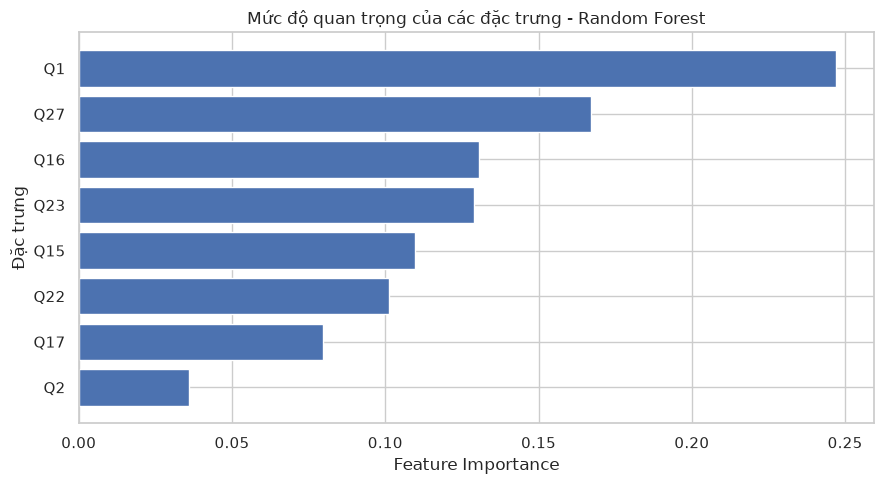

In [58]:
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Đặc trưng"][::-1],
    feature_importance["Mức độ quan trọng"][::-1]
)

plt.title("Mức độ quan trọng của các đặc trưng - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

Nhận xét Feature Importance:
- Các biến được xếp hạng theo mức đóng góp vào dự đoán của Random Forest trong tập dữ liệu này.
- Feature importance không cho biết chiều tác động và không chứng minh quan hệ nhân quả.
- Diễn giải thứ hạng từ bảng vừa tính, không dùng các giá trị của Tanzania.

Feature importance giúp mô tả cách Random Forest sử dụng các biến trong dự đoán, nhưng không chứng minh biến đó gây ra câu trả lời Q24. Các giá trị phụ thuộc bộ dữ liệu, cách chia mẫu và cấu hình mô hình.

## TỔNG KẾT KẾT QUẢ 5 MÔ HÌNH

In [59]:
# Sắp xếp các mô hình theo F1-score giảm dần
comparison_sorted = comparison_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

display(comparison_sorted.round(4))

best_model = comparison_sorted.iloc[0]

print("Mô hình có F1-score cao nhất:", best_model["Mô hình"])
print("F1-score:", round(best_model["F1-score"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("PR-AUC:", round(best_model["PR-AUC"], 4))

,Mô hình,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Random Forest,0.6821,0.2087,0.48,0.2909,0.5881,0.2312
1,Decision Tree,0.5761,0.1688,0.54,0.2571,0.5885,0.2152
2,Gradient Boosting,0.8655,0.5556,0.05,0.0917,0.5813,0.2161
3,Logistic Regression,0.8628,0.0000,0.00,0.0000,0.6117,0.2016
4,Neural Network,0.8641,0.0000,0.00,0.0000,0.4648,0.1477


Mô hình có F1-score cao nhất: Random Forest
F1-score: 0.2909
Recall: 0.48
PR-AUC: 0.2312


## KẾT LUẬN

Kết quả notebook được giới hạn ở mẫu GSHS Tanzania 2014: CSV có 3.793 bản ghi; Q24 có 3.677 câu trả lời hợp lệ, trong đó 500 (13,6%) là “Có” theo codebook. So sánh mô hình sử dụng một lần chia train/test có phân tầng và các chỉ số của lớp dương. Kết quả không đại diện cho tình hình hiện tại, chưa áp dụng trọng số/tầng/cụm khảo sát và không chứng minh quan hệ nhân quả. Câu trả lời Q24 cùng các dự đoán không phải chẩn đoán hoặc sàng lọc lâm sàng.